# 1. Model training, tuning and evaluation

**Component 3, Electricity Demand Forecasting with Scenario Analysis** | Dewmini D.M.D.P (IT22630216)

**What this notebook does, in order**

1. **Configuration**: every parameter in one place.
2. **Load and explore** the data.
3. **Split** into training and test sets.
4. **Baseline comparison** of three model families with their initial parameters.
5. **Optuna tuning** of the best family (training data only, cross-validated).
6. **Final model**: refit with the chosen parameters, then evaluate once on the unseen test set.
7. **Checks**: overfitting (train vs test), chronological split, diagnostics, feature importance.
8. **Save** the model and the files the API reads.

**Data:** `notebooks/load_forecasting_dataset_corrected.csv` (189,888 fifteen-minute records, 2020 to 2025, 13 input features).

**Outputs written** (the same files `scripts/train_model.py` writes):
`backend/saved_models/forecast_model.pkl`, `model_metadata.json`, `reference.json`.

## Step 1: Configuration (all parameters in one place)
Nothing below this cell uses a hidden number: split ratio, random seeds, model parameters, the Optuna budget and the search space are all defined here.

| Group | Parameter | Value | Meaning |
|---|---|---|---|
| Split | `TEST_SIZE` | 0.2 | 20% of rows are held back for the final test |
| Reproducibility | `SEED` | 42 | fixes every random choice so results can be repeated |
| Random Forest | `RF_PARAMS` | 100 trees, depth 10 | baseline settings |
| Gradient Boosting | `INITIAL_PARAMS` | 300 trees, depth 5, learning rate 0.08, subsample 0.8 | the starting point that tuning must beat |
| Optuna | `n_trials` | 20 | how many parameter combinations to try |
| Optuna | `cv_folds` | 3 | each combination is scored by 3-fold cross-validation |
| Optuna | `search_rows` | 20,000 | tuning uses a sample of the **training** rows so it stays fast |

In [1]:
import json
import joblib
import optuna
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import KFold, cross_val_score, train_test_split

ROOT = Path.cwd().parent
DATA = ROOT / 'notebooks' / 'load_forecasting_dataset_corrected.csv'
MODELS = ROOT / 'backend' / 'saved_models'        # the API loads the model from here
plt.rcParams['figure.dpi'] = 100

# The 13 inputs the model uses. The ORDER matters: the API must send columns in this exact order.
FEATURES = ['Temperature (°C)', 'Humidity (%)', 'Wind Speed (m/s)', 'Rainfall (mm)', 'Solar Irradiance (W/m²)', 'GDP (LKR)',
            'Per Capita Energy Use (kWh)', 'Electricity Price (LKR/kWh)', 'Day of Week', 'Hour of Day', 'Month', 'Public Event', 'Poya Day']
TARGET = 'Load Demand (kW)'

# ======================= CONFIGURATION: every parameter used below lives here =======================
SEED = 42
TEST_SIZE = 0.2                      # 80% train / 20% test
INITIAL_PARAMS = dict(n_estimators=300, max_depth=5, learning_rate=0.08, subsample=0.8)   # Gradient Boosting starting point
RF_PARAMS = dict(n_estimators=100, max_depth=10)
OPTUNA = dict(n_trials=20, cv_folds=3, search_rows=20_000, sampler_seed=42)               # tuning budget
# Optuna search space for Gradient Boosting: name -> (low, high, kind)
SEARCH_SPACE = dict(
    n_estimators=(100, 300, 'int-step50'),    # number of trees
    max_depth=(3, 7, 'int'),                  # how deep each tree can grow
    learning_rate=(0.03, 0.2, 'log-float'),   # how strongly each new tree corrects the last
    subsample=(0.6, 1.0, 'float'),            # share of rows each tree sees
    min_samples_leaf=(5, 80, 'log-int'),      # smallest group of rows allowed in a leaf
    max_features=(0.5, 1.0, 'float'))         # share of features considered at each split
# =====================================================================================================

def metrics(y_true, y_pred):
    """R2 (share of variation explained), MAE (average miss, kW), RMSE (like MAE but punishes big misses)."""
    return dict(r2=float(r2_score(y_true, y_pred)), mae=float(mean_absolute_error(y_true, y_pred)),
                rmse=float(np.sqrt(mean_squared_error(y_true, y_pred))))

/Users/shivakumar/Desktop/Component1-FULL-share/final_research/venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Step 2: Load and explore the data
Two quick views of what drives demand: the **daily pattern** and the **effect of temperature**. The model should learn both.

In [2]:
df = pd.read_csv(DATA)
df['Timestamp'] = pd.to_datetime(df['Timestamp'])
print('Rows:', len(df), '| Columns:', df.shape[1])
print('Period:', df['Timestamp'].min().date(), 'to', df['Timestamp'].max().date(), '(15-minute readings)')
print('Missing values:', int(df[FEATURES + [TARGET]].isna().sum().sum()))
df[FEATURES + [TARGET]].describe().T[['mean', 'std', 'min', 'max']].round(1)

Rows: 189888 | Columns: 17
Period: 2020-01-01 to 2025-05-31 (15-minute readings)
Missing values: 0


,mean,std,min,max
Temperature (°C),28.0,2.0,19.1,37.1
Humidity (%),80.0,5.0,57.9,101.1
Wind Speed (m/s),2.0,1.0,-2.8,6.3
Rainfall (mm),5.0,5.0,0.0,59.2
Solar Irradiance (W/m²),249.9,50.0,53.6,449.5
GDP (LKR),1000.1,50.0,779.6,1251.7
Per Capita Energy Use (kWh),499.9,20.0,407.1,592.3
Electricity Price (LKR/kWh),25.0,5.0,3.3,47.4
Day of Week,3.0,2.0,0.0,6.0
Hour of Day,11.5,6.9,0.0,23.0


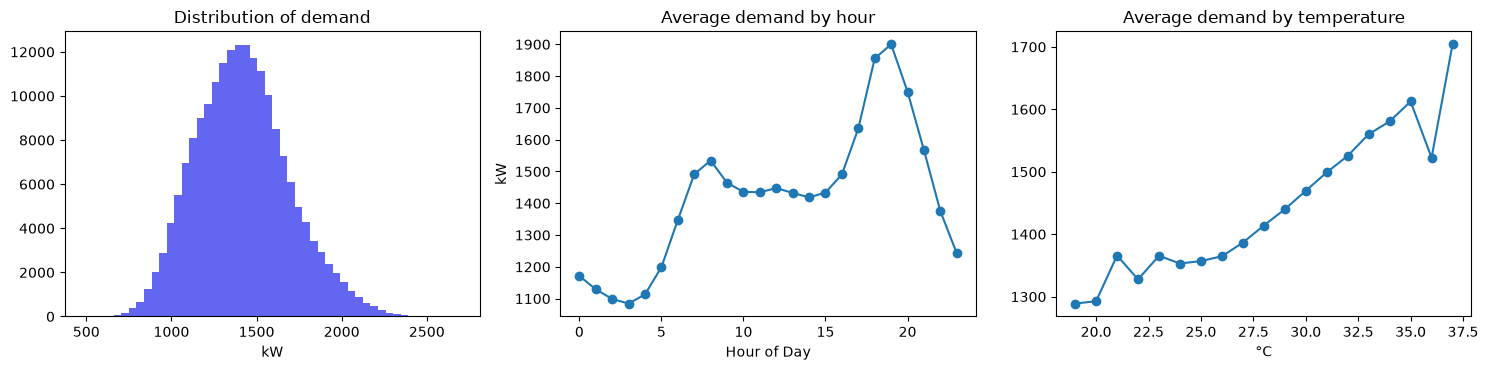

In [3]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
ax[0].hist(df[TARGET], bins=50, color='#6366f1'); ax[0].set_title('Distribution of demand'); ax[0].set_xlabel('kW')
df.groupby('Hour of Day')[TARGET].mean().plot(ax=ax[1], marker='o'); ax[1].set_title('Average demand by hour'); ax[1].set_ylabel('kW')
df.assign(T=df['Temperature (°C)'].round()).groupby('T')[TARGET].mean().plot(ax=ax[2], marker='o'); ax[2].set_title('Average demand by temperature')
ax[2].set_xlabel('°C'); plt.tight_layout(); plt.show()

## Step 3: Train / test split
`TEST_SIZE` of the rows are **never shown during training or tuning**; they measure how well the final model generalises.

In [4]:
X, y = df[FEATURES], df[TARGET]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=TEST_SIZE, random_state=SEED)
print(f'Train rows: {len(X_train):,} | Test rows: {len(X_test):,}')

Train rows: 151,910 | Test rows: 37,978


## Step 4: Baseline comparison of three model families
All three are trained on the same training rows with their initial parameters (from the configuration) and judged on the same test rows.

* **Linear Regression**: straight-line relationships (simple baseline).
* **Random Forest**: averages many independent decision trees.
* **Gradient Boosting**: builds trees one after another, each correcting the previous trees' mistakes. Good at curved relationships such as
  "air-conditioning only starts above about 26 °C".

The best family is then tuned in Step 5.

In [5]:
candidates = {
    'Linear Regression': LinearRegression(),
    'Random Forest': RandomForestRegressor(random_state=SEED, n_jobs=-1, **RF_PARAMS),
    'Gradient Boosting': GradientBoostingRegressor(random_state=SEED, **INITIAL_PARAMS),
}
comparison = {}
for name, m in candidates.items():
    m.fit(X_train, y_train)                                        # learn from the training rows only
    s = metrics(y_test, m.predict(X_test))                         # judge on the unseen test rows
    comparison[name] = dict(test_r2=s['r2'], test_mae=s['mae'], test_rmse=s['rmse'])
    print(f"{name:20s} R2={s['r2']:.4f}  MAE={s['mae']:.1f} kW  RMSE={s['rmse']:.1f} kW")

family = max(comparison, key=lambda n: comparison[n]['test_r2'])
assert family == 'Gradient Boosting', 'the tuning in Step 5 is written for Gradient Boosting'
print('\nBest family:', family)
pd.DataFrame(comparison).T.round(3)

Linear Regression    R2=0.4379  MAE=160.1 kW  RMSE=205.5 kW


Random Forest        R2=0.7768  MAE=102.9 kW  RMSE=129.5 kW


Gradient Boosting    R2=0.8250  MAE=91.5 kW  RMSE=114.6 kW

Best family: Gradient Boosting


,test_r2,test_mae,test_rmse
Linear Regression,0.438,160.112,205.491
Random Forest,0.777,102.857,129.480
Gradient Boosting,0.825,91.514,114.646


## Step 5: Hyperparameter tuning with Optuna
**Hyperparameters** are the settings chosen *before* training (number of trees, depth, learning rate, ...). Instead of guessing, Optuna searches for good values:

1. It proposes a parameter combination from the **search space** defined in Step 1 (using a TPE sampler, which learns from earlier trials where good values lie).
2. Each combination is scored with **3-fold cross-validation on the training data only**: the training rows are split into 3 parts, the model trains on 2 and is scored on the third, rotating, and the average RMSE is the score.
3. After `n_trials` combinations, the best (lowest RMSE) is kept.

**Why this is fair:** the test set is not used anywhere in this step, so the final test score is not tuned to the test data. To stay fast, the search uses a sample of `search_rows` training rows.

In [6]:
optuna.logging.set_verbosity(optuna.logging.WARNING)
X_search = X_train.sample(OPTUNA['search_rows'], random_state=SEED)      # a sample of the TRAINING rows only
y_search = y_train.loc[X_search.index]
cv = KFold(n_splits=OPTUNA['cv_folds'], shuffle=True, random_state=SEED)

def cv_rmse(params):
    """Cross-validated RMSE of Gradient Boosting with these parameters (lower is better)."""
    scores = cross_val_score(GradientBoostingRegressor(random_state=SEED, **params), X_search, y_search, cv=cv,
                             scoring='neg_root_mean_squared_error')
    return float(-scores.mean())

def suggest(trial):
    """Turn the SEARCH_SPACE from Step 1 into Optuna suggestions."""
    p = {}
    for k, (lo, hi, kind) in SEARCH_SPACE.items():
        if kind == 'int-step50': p[k] = trial.suggest_int(k, lo, hi, step=50)
        elif kind == 'int': p[k] = trial.suggest_int(k, lo, hi)
        elif kind == 'log-int': p[k] = trial.suggest_int(k, lo, hi, log=True)
        elif kind == 'log-float': p[k] = trial.suggest_float(k, lo, hi, log=True)
        else: p[k] = trial.suggest_float(k, lo, hi)
    return p

initial_cv = cv_rmse(INITIAL_PARAMS)        # the score the tuned parameters have to beat, on the same folds
study = optuna.create_study(direction='minimize', sampler=optuna.samplers.TPESampler(seed=OPTUNA['sampler_seed']))
study.optimize(lambda trial: cv_rmse(suggest(trial)), n_trials=OPTUNA['n_trials'])

print(f"Cross-validated RMSE  |  initial parameters: {initial_cv:.2f} kW  |  best of {OPTUNA['n_trials']} trials: {study.best_value:.2f} kW")
print('Best parameters found:')
for k, v in study.best_params.items():
    print(f'   {k:18s} {v}')

Cross-validated RMSE  |  initial parameters: 118.09 kW  |  best of 20 trials: 116.65 kW
Best parameters found:
   n_estimators       250
   max_depth          3
   learning_rate      0.09835741753336463
   subsample          0.8602615976200904
   min_samples_leaf   39
   max_features       0.8694849120337964


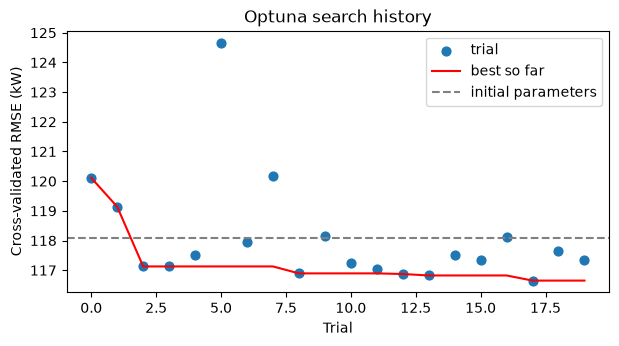

,number,value,params_learning_rate,params_max_depth,params_max_features,params_min_samples_leaf,params_n_estimators,params_subsample
17,17,116.651,0.098,3,0.869,39,250,0.860
13,13,116.824,0.161,3,0.924,74,200,0.824
12,12,116.872,0.163,3,0.959,37,200,0.974
8,8,116.894,0.189,3,0.947,68,200,0.910
11,11,117.047,0.113,4,0.987,46,200,0.987


In [7]:
# How the search progressed: each dot is one trial; the line is the best score so far.
trials = study.trials_dataframe()
best_so_far = trials['value'].cummin()
plt.figure(figsize=(7, 3.4))
plt.scatter(trials['number'], trials['value'], s=40, label='trial')
plt.plot(trials['number'], best_so_far, color='red', label='best so far')
plt.axhline(initial_cv, color='grey', ls='--', label='initial parameters')
plt.xlabel('Trial'); plt.ylabel('Cross-validated RMSE (kW)'); plt.title('Optuna search history'); plt.legend(); plt.show()

trials[['number', 'value'] + [c for c in trials.columns if c.startswith('params_')]].sort_values('value').head(5).round(3)

## Step 6: Final model
**Decision rule (made on cross-validation, not on the test set):** use the tuned parameters only if they beat the initial parameters in
cross-validation. The chosen model is then refitted on the **full** training set and evaluated once on the test set.

Using tuned parameters:
{
  "n_estimators": 250,
  "max_depth": 3,
  "learning_rate": 0.09835741753336463,
  "subsample": 0.8602615976200904,
  "min_samples_leaf": 39,
  "max_features": 0.8694849120337964
}


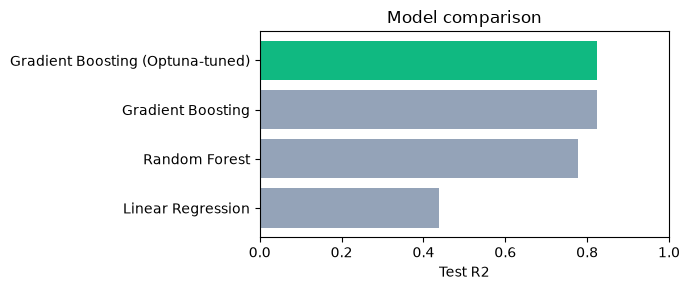

,test_r2,test_mae,test_rmse
Linear Regression,0.438,160.112,205.491
Random Forest,0.777,102.857,129.480
Gradient Boosting,0.825,91.514,114.646
Gradient Boosting (Optuna-tuned),0.824,91.769,115.077


In [8]:
use_tuned = study.best_value < initial_cv
final_params = {**INITIAL_PARAMS, **study.best_params} if use_tuned else dict(INITIAL_PARAMS)
print('Using tuned parameters:' if use_tuned else 'Keeping initial parameters:')
print(json.dumps(final_params, indent=2, default=float))

model = GradientBoostingRegressor(random_state=SEED, **final_params).fit(X_train, y_train)
tuned_name = 'Gradient Boosting (Optuna-tuned)'
s = metrics(y_test, model.predict(X_test))
comparison[tuned_name] = dict(test_r2=s['r2'], test_mae=s['mae'], test_rmse=s['rmse'])
best_name = tuned_name if use_tuned else family

fig, ax = plt.subplots(figsize=(7, 3))
ax.barh(list(comparison), [comparison[n]['test_r2'] for n in comparison],
        color=['#10b981' if n == best_name else '#94a3b8' for n in comparison])
ax.set_xlabel('Test R2'); ax.set_xlim(0, 1); ax.set_title('Model comparison'); plt.tight_layout(); plt.show()
pd.DataFrame(comparison).T.round(3)

### Reading the tuning result
Compare the **initial** and **tuned** Gradient Boosting rows above. Tuning can only help as much as the data allows: demand always contains some
unpredictable variation (the *irreducible error*), and once a model reaches that floor, better settings change the score very little.
If the two rows are nearly equal, the initial model was already close to the best achievable, and that is a valid finding, not a failure of the search.

In [9]:
gain = pd.DataFrame({'Initial parameters': comparison['Gradient Boosting'], 'Optuna-tuned': comparison[tuned_name]}).T
gain.loc['difference (tuned - initial)'] = gain.loc['Optuna-tuned'] - gain.loc['Initial parameters']
print(f'Cross-validated RMSE on the search sample: initial {initial_cv:.2f} -> tuned {study.best_value:.2f} kW')
gain.round(4)

Cross-validated RMSE on the search sample: initial 118.09 -> tuned 116.65 kW


,test_r2,test_mae,test_rmse
Initial parameters,0.8250,91.5142,114.6463
Optuna-tuned,0.8237,91.7685,115.0772
difference (tuned - initial),-0.0013,0.2543,0.4309


## Step 7: Overfitting check (train vs test)
An overfitted model scores very well on the data it trained on and noticeably worse on new data.
Close scores mean the model has genuinely learned the pattern.

In [10]:
train_s, test_s = metrics(y_train, model.predict(X_train)), metrics(y_test, model.predict(X_test))
pd.DataFrame({'Train': train_s, 'Test': test_s}).T.round(3)

,r2,mae,rmse
Train,0.828,91.063,114.228
Test,0.824,91.769,115.077


## Step 8: Chronological check
A random split mixes all years together. Real forecasting predicts the **future**, so we also train on the first 80% of *time* and test on
the last 20%. A similar score means the result does not depend on a lucky random split.

In [11]:
cut = int(len(df) * 0.8)                                          # rows are already in time order
chrono_model = GradientBoostingRegressor(random_state=SEED, **final_params).fit(X.iloc[:cut], y.iloc[:cut])
chrono = metrics(y.iloc[cut:], chrono_model.predict(X.iloc[cut:]))
print(f"Chronological test: R2={chrono['r2']:.4f}  MAE={chrono['mae']:.1f} kW")

Chronological test: R2=0.8261  MAE=91.7 kW


## Step 9: Diagnostics
* **Actual vs predicted**: points close to the red diagonal are good predictions.
* **Residuals** (actual minus predicted): should form a bell shape centred on 0. A shifted or skewed shape would mean systematic bias.

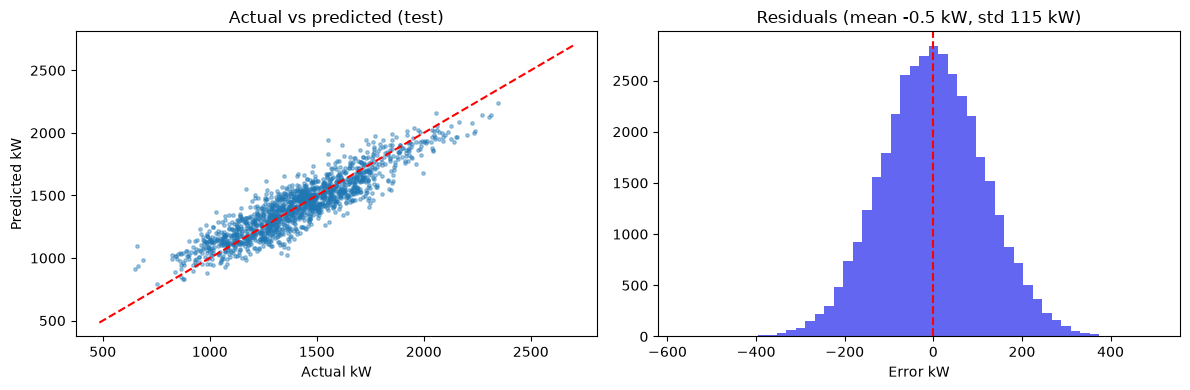

In [12]:
pred_test = model.predict(X_test)
residual = y_test.to_numpy() - pred_test

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
idx = np.random.default_rng(1).choice(len(y_test), 1500, replace=False)         # a sample keeps the plot readable
ax[0].scatter(y_test.to_numpy()[idx], pred_test[idx], s=6, alpha=0.4)
lo, hi = y_test.min(), y_test.max(); ax[0].plot([lo, hi], [lo, hi], 'r--')
ax[0].set_title('Actual vs predicted (test)'); ax[0].set_xlabel('Actual kW'); ax[0].set_ylabel('Predicted kW')
ax[1].hist(residual, bins=50, color='#6366f1'); ax[1].axvline(0, color='r', ls='--')
ax[1].set_title(f'Residuals (mean {residual.mean():.1f} kW, std {residual.std():.0f} kW)'); ax[1].set_xlabel('Error kW')
plt.tight_layout(); plt.show()

## Step 10: What does the model rely on?
Feature importance shows how much each input contributes to the trees' decisions. The hour of day should dominate because of the daily rhythm.

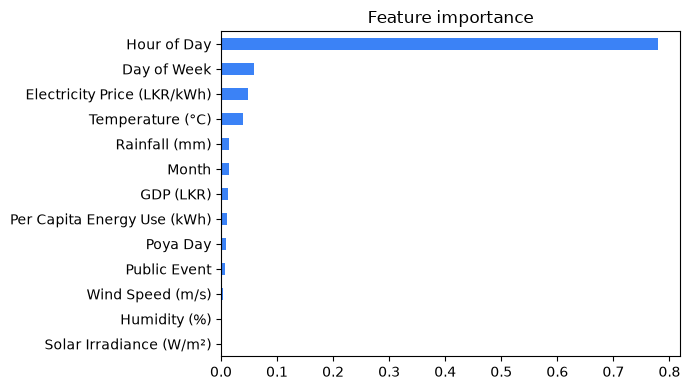

In [13]:
importances = dict(zip(FEATURES, map(float, model.feature_importances_)))
pd.Series(importances).sort_values().plot(kind='barh', figsize=(7, 4), color='#3b82f6')
plt.title('Feature importance'); plt.tight_layout(); plt.show()

## Step 11: Save the model and the files the API reads
* `forecast_model.pkl`: the trained model.
* `model_metadata.json`: feature names (in order), metrics, comparison, importances, the **final hyperparameters** and a record of the **Optuna search**.
* `reference.json`: input ranges, a "typical day" and a default supply limit, used by the dashboard and the Grid Decision Lab.

In [14]:
joblib.dump(model, MODELS / 'forecast_model.pkl')

metadata = dict(
    model_type=type(model).__name__, feature_names=FEATURES, target_column=TARGET,
    model_performance=dict(train_r2=train_s['r2'], test_r2=test_s['r2'], train_mae=train_s['mae'], test_mae=test_s['mae'],
                           train_rmse=train_s['rmse'], test_rmse=test_s['rmse'],
                           chronological_test_r2=chrono['r2'], chronological_test_mae=chrono['mae']),
    model_comparison=comparison, feature_importances=importances,
    hyperparameters=final_params,                                   # the exact parameters of the deployed model
    optuna=dict(n_trials=OPTUNA['n_trials'], cv_folds=OPTUNA['cv_folds'], search_rows=OPTUNA['search_rows'],
                search_space={k: list(v) for k, v in SEARCH_SPACE.items()}, initial_params=INITIAL_PARAMS,
                initial_cv_rmse=initial_cv, best_cv_rmse=float(study.best_value), best_params=study.best_params,
                tuned_params_deployed=bool(use_tuned)),
    data_info=dict(total_samples=len(df), train_samples=len(X_train), test_samples=len(X_test),
                   source='notebooks/load_forecasting_dataset_corrected.csv'),
    deployment_decision=(f"{best_name} deployed. Gradient Boosting was the best of three families on test R2; its parameters were then "
                         f"tuned with Optuna ({OPTUNA['n_trials']} trials, {OPTUNA['cv_folds']}-fold CV on training data only)"
                         + (' and the tuned parameters beat the initial ones in cross-validation.' if use_tuned else
                            ', but the initial parameters were better in cross-validation and were kept.')),
)
json.dump(metadata, open(MODELS / 'model_metadata.json', 'w'), indent=2)

# Reference data: ranges and a typical day for the UI
numeric = [c for c in FEATURES if c not in ('Day of Week', 'Hour of Day', 'Month', 'Public Event', 'Poya Day')]
ranges = {c: dict(min=float(df[c].min()), p5=float(df[c].quantile(.05)), p95=float(df[c].quantile(.95)),
                  max=float(df[c].max()), mean=float(df[c].mean())) for c in numeric}
typical = {c: round(float(df[c].mean()), 2) for c in numeric}
typical.update({'Day of Week': 2, 'Hour of Day': 19, 'Month': 6, 'Public Event': 0, 'Poya Day': 0})   # a Wednesday evening in June

# Default supply limit: 20% headroom over the peak of a typical day, so a normal day reads "Safe" in the dashboard
typical_day = pd.DataFrame([{**typical, 'Hour of Day': h} for h in range(24)])[FEATURES]
capacity = float(np.ceil(model.predict(typical_day).max() * 1.2 / 50) * 50)
json.dump(dict(ranges=ranges, typical=typical, features=FEATURES, default_capacity_kw=capacity,
               demand_percentiles={str(q): float(df[TARGET].quantile(q / 100)) for q in (5, 25, 50, 75, 95, 99)}),
          open(MODELS / 'reference.json', 'w'), indent=2)
print('Saved model, metadata and reference. Default supply limit:', capacity, 'kW')

Saved model, metadata and reference. Default supply limit: 2400.0 kW


## Summary
* Gradient Boosting was the best of three model families on unseen data.
* Optuna then tuned its parameters using cross-validation on the training data only; the tuned parameters replace the initial ones only if they win in cross-validation.
* Train and test scores are close and the chronological split agrees, so overfitting is not a concern.
* **Next:** `2_uncertainty_calibration.ipynb` measures how wrong the model can be and turns that into prediction ranges and risk probabilities.